In [1]:
import pandas as pd

models = pd.read_csv("../data/raw/Model.csv")
mutations = pd.read_csv("../data/raw/OmicsSomaticMutationsMatrixDamaging.csv")
crispr = pd.read_csv("../data/raw/CRISPRGeneEffect.csv")

for name, df in [("Model", models), ("Mutations", mutations), ("CRISPR", crispr)]:
    print(f"--- {name}: {df.shape[0]} rows x {df.shape[1]} columns")
    print(list(df.columns[:8]))
    print()

--- Model: 2554 rows x 48 columns
['ModelID', 'PatientID', 'CellLineName', 'StrippedCellLineName', 'DepmapModelType', 'OncotreeLineage', 'OncotreePrimaryDisease', 'OncotreeSubtype']

--- Mutations: 3807 rows x 19738 columns
['Unnamed: 0', 'SequencingID', 'ModelID', 'ModelConditionID', 'IsDefaultEntryForModel', 'IsDefaultEntryForMC', 'FAM87B (400728)', 'LINC02593 (100130417)']

--- CRISPR: 1361 rows x 18435 columns
['Unnamed: 0', 'A1BG (1)', 'A1CF (29974)', 'A2M (2)', 'A2ML1 (144568)', 'A3GALT2 (127550)', 'A4GALT (53947)', 'A4GNT (51146)']



In [2]:
# 1. Keep one sequencing entry per cell line
print("Default-entry values:", mutations["IsDefaultEntryForModel"].unique())
mut = mutations[mutations["IsDefaultEntryForModel"].astype(str).str.lower().isin(["yes", "true"])]
mut = mut.set_index("ModelID")
mut = mut[~mut.index.duplicated()]
print("Cell lines with mutation data:", len(mut))

# 2. BRCA2 damaging-mutation status
brca2_col = [c for c in mut.columns if c.startswith("BRCA2 (")][0]
print("\nBRCA2 damaging mutation counts per cell line:")
print(mut[brca2_col].value_counts())

# 3. PARP1 dependency from CRISPR
crispr = crispr.rename(columns={"Unnamed: 0": "ModelID"}).set_index("ModelID")
parp1_col = [c for c in crispr.columns if c.startswith("PARP1 (")][0]

# 4. Combine: only cell lines that have both
df = pd.DataFrame({"BRCA2_damaging": mut[brca2_col]}).join(crispr[[parp1_col]], how="inner")
df = df.rename(columns={parp1_col: "PARP1_effect"})
print("\nCell lines with both mutation and CRISPR data:", len(df))
df.head()

Default-entry values: <StringArray>
['Yes', 'No']
Length: 2, dtype: str
Cell lines with mutation data: 2395

BRCA2 damaging mutation counts per cell line:
BRCA2 (675)
0.0    2320
1.0      63
2.0      12
Name: count, dtype: int64

Cell lines with both mutation and CRISPR data: 1361


,BRCA2_damaging,PARP1_effect
ModelID,,
ACH-002059,0.0,-0.164699
ACH-000402,0.0,-0.090170
ACH-002811,0.0,-0.434089
ACH-000693,0.0,-0.108605
ACH-001991,1.0,-0.342006


Matplotlib is building the font cache; this may take a moment.


BRCA2_status
Wild-type     1319
1 damaging      33
2 damaging       9
Name: count, dtype: int64
1 damaging vs wild-type: median -0.214 vs -0.188, p = 0.0955
2 damaging vs wild-type: median -0.203 vs -0.188, p = 0.296


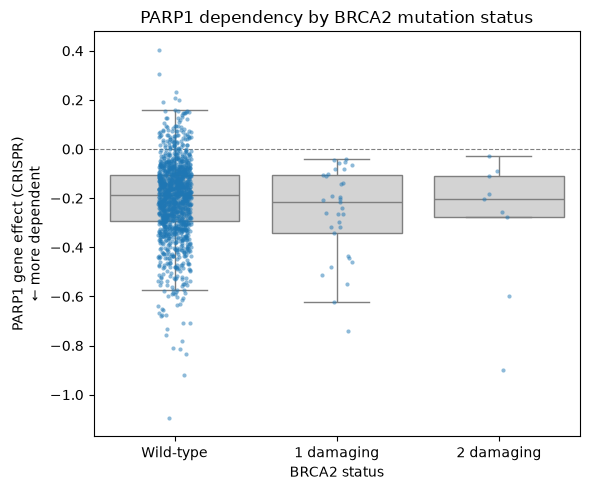

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import mannwhitneyu

# Label BRCA2 status
labels = {0: "Wild-type", 1: "1 damaging", 2: "2 damaging"}
df["BRCA2_status"] = df["BRCA2_damaging"].map(labels)
order = ["Wild-type", "1 damaging", "2 damaging"]
print(df["BRCA2_status"].value_counts().reindex(order))

# Statistical test: each mutant group vs wild-type
wt = df.loc[df["BRCA2_status"] == "Wild-type", "PARP1_effect"]
for group in ["1 damaging", "2 damaging"]:
    g = df.loc[df["BRCA2_status"] == group, "PARP1_effect"]
    stat, p = mannwhitneyu(g, wt, alternative="less")
    print(f"{group} vs wild-type: median {g.median():.3f} vs {wt.median():.3f}, p = {p:.3g}")

# Plot
fig, ax = plt.subplots(figsize=(6, 5))
sns.boxplot(data=df, x="BRCA2_status", y="PARP1_effect", order=order, showfliers=False, color="lightgrey", ax=ax)
sns.stripplot(data=df, x="BRCA2_status", y="PARP1_effect", order=order, size=3, alpha=0.5, ax=ax)
ax.axhline(0, ls="--", c="grey", lw=0.8)
ax.set_xlabel("BRCA2 status")
ax.set_ylabel("PARP1 gene effect (CRISPR)\n← more dependent")
ax.set_title("PARP1 dependency by BRCA2 mutation status")
plt.tight_layout()
plt.savefig("../results/figures/parp1_by_brca2.png", dpi=200)
plt.show()